### **Naive Bayes End-to-End ML Pipeline — Group Lab (3 Members)**

**Goal:** As a group of **3**, build a complete pipeline that predicts Titanic passenger survival with **Naive Bayes** — from raw data all the way to a final, evaluated model. The lab is split into **3 parts**, one per group member, but **everyone should read and understand every part** — you'll need each other's outputs to finish the pipeline.

**Dataset:** We'll use `seaborn`'s **built-in** Titanic dataset — no download or upload needed:
```python
titanic = sns.load_dataset('titanic')
```
(If your instructor asks you to use a different/self-generated dataset instead, the same structure below still applies — just swap the loading step.)

**How the 3 parts connect (the pipeline, in order):**

| Part | Member | Focus | Concepts Covered |
|---|---|---|---|
| **1** | **A** | Explore the raw data | EDA, Data Visualization, Bayes' Theorem (by hand) |
| **2** | **B** | Clean & transform the data | Missing Values, Binning, Binarization, Ordinal/One-Hot/Label Encoding, Column Transformer, Function/Power Transformer, Standardization & Normalization |
| **3** | **C** | Build & evaluate the model | Naive Bayes (from scratch + `sklearn`), Cross-Validation, Evaluation Metrics |

**Rule:** Member B's final output (`X_train_final`, `X_test_final`, `y_train`, `y_test`) is exactly what Member C needs as input. Member A's Section 1.7 (Bayes' Theorem by hand) is the conceptual foundation Member C will re-use in Section 3.1. **Talk to each other before starting your part.**

Cells marked `# TODO` are where you write your own code. Everything else (imports, structure, explanations) is provided to keep the group in sync.

#### **0. Shared Setup (Everyone Runs This First)**

Run this section before splitting into your parts — it loads the libraries and the dataset every part depends on.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set(style='whitegrid')


In [ ]:
# Built-in dataset - no download required
titanic = sns.load_dataset('titanic')
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**A quick look at what we're working with:** each row is one passenger. Key columns: `survived` (target, 0/1), `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `alive` (text version of `survived`), `deck` (mostly missing).

#### **Part 1 (Member A): Exploratory Data Analysis & Bayes' Theorem Foundations**

**Your job:** understand the raw data before anyone touches it — its shape, quality issues, and the patterns that make Naive Bayes a sensible model choice here.

**1.1 Dataset Structure**

Check the shape, column data types, and general info of `titanic`.

In [ ]:
# TODO: print the shape of the dataset
# TODO: use .info() to see column dtypes and non-null counts

print(titanic.shape)
titanic.info()

(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**1.2 Statistical Summary**

`.describe()` gives count/mean/std/min/max/quartiles for numeric columns — a first look at scale and possible skew (e.g., compare `fare`'s mean vs its median/50%).

In [ ]:
# TODO: call .describe() on titanic
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**1.3 Missing Value Analysis**

Which columns have missing data, and how much? This will guide Member B's cleaning strategy in Part 2.

             missing  percent
survived           0     0.00
pclass             0     0.00
sex                0     0.00
age              177    19.87
sibsp              0     0.00
parch              0     0.00
fare               0     0.00
embarked           2     0.22
class              0     0.00
who                0     0.00
adult_male         0     0.00
deck             688    77.22
embark_town        2     0.22
alive              0     0.00
alone              0     0.00


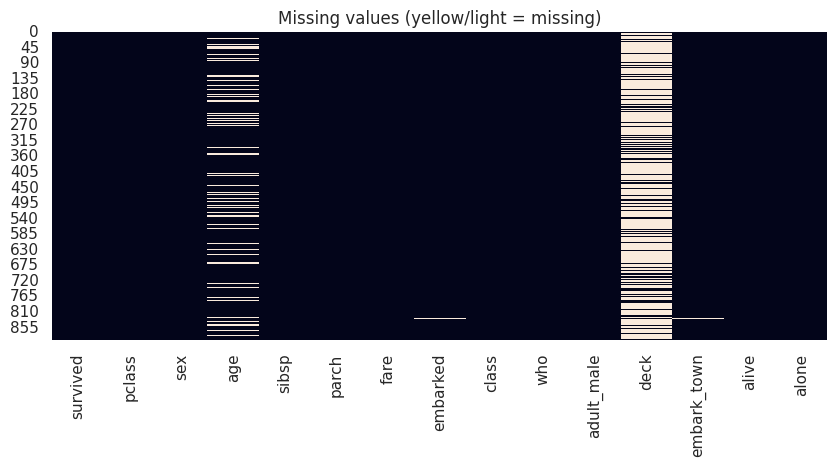

In [ ]:
# TODO: compute titanic.isnull().sum()
# TODO: also compute it as a percentage of total rows

# TODO (visualization): plot a heatmap of missing values, e.g.
# sns.heatmap(titanic.isnull(), cbar=False)

missing_counts = titanic.isnull().sum()
missing_pct = (titanic.isnull().sum() / len(titanic) * 100).round(2)
print(pd.DataFrame({'missing': missing_counts, 'percent': missing_pct}))

plt.figure(figsize=(10, 4))
sns.heatmap(titanic.isnull(), cbar=False)
plt.title('Missing values (yellow/light = missing)')
plt.show()

**1.4 Target Variable Distribution**

Is `survived` balanced or imbalanced? This matters for how we should judge "accuracy" later in Part 3.

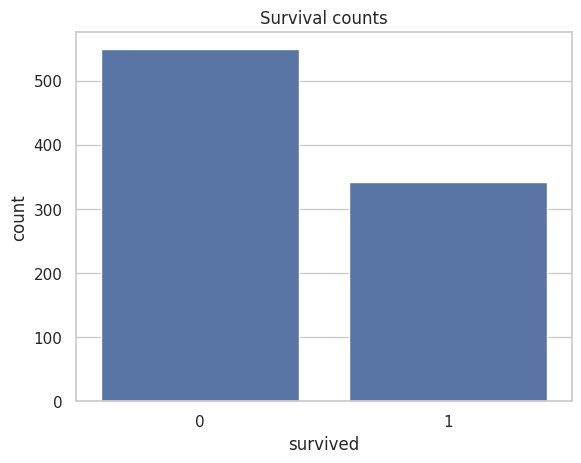

survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [ ]:
# TODO: sns.countplot the 'survived' column
# TODO: print the exact percentage split (value_counts(normalize=True))
sns.countplot(x='survived', data=titanic)
plt.title('Survival counts')
plt.show()
print(titanic['survived'].value_counts(normalize=True))

**1.5 Univariate Analysis**

Look at `age` and `fare` individually — shape of distribution, and whether they look skewed (relevant for Member B's transformation step later).

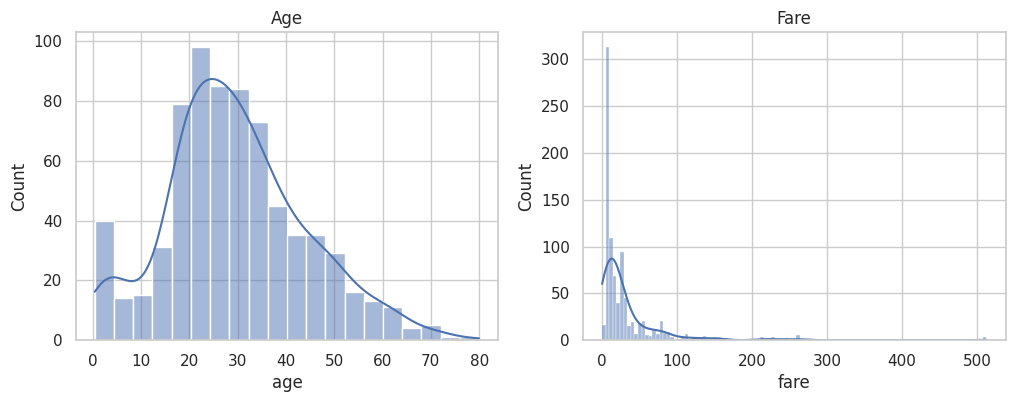

age skew : 0.38910778230082704
fare skew: 4.787316519674893


In [ ]:
# TODO: plot a histogram (with KDE) of 'age'
# TODO: plot a histogram (with KDE) of 'fare'
# TODO: print titanic['age'].skew() and titanic['fare'].skew()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(titanic['age'].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Age')
sns.histplot(titanic['fare'], kde=True, ax=axes[1])
axes[1].set_title('Fare')
plt.show()

print('age skew :', titanic['age'].skew())
print('fare skew:', titanic['fare'].skew())

**1.6 Bivariate Analysis — Does Survival Depend on Sex and Class?**

Compute and visualize survival rate broken down by `sex`, and separately by `pclass`.

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


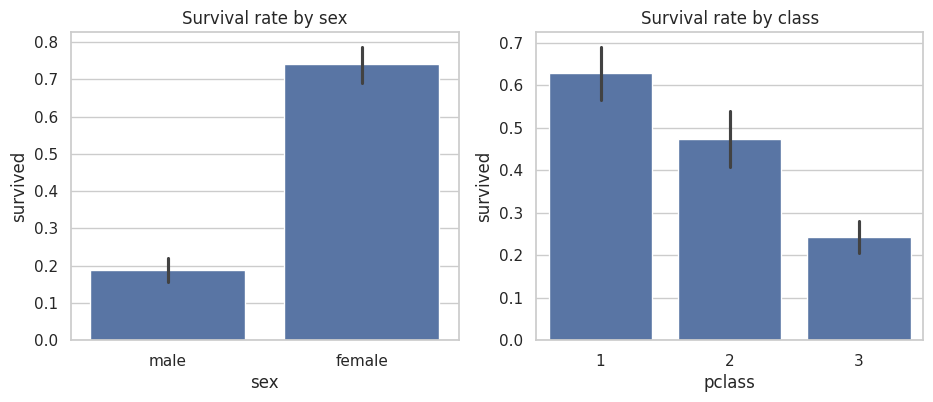

In [ ]:
# TODO: titanic.groupby('sex')['survived'].mean()
# TODO: titanic.groupby('pclass')['survived'].mean()
# TODO: visualize both with sns.barplot or sns.catplot

print(titanic.groupby('sex')['survived'].mean())
print(titanic.groupby('pclass')['survived'].mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x='sex', y='survived', data=titanic, ax=axes[0])
axes[0].set_title('Survival rate by sex')
sns.barplot(x='pclass', y='survived', data=titanic, ax=axes[1])
axes[1].set_title('Survival rate by class')
plt.show()

**1.7 Connecting to Bayes' Theorem**

Recall **Bayes' Theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Let's estimate, **by hand**, the probability a passenger survived *given* they were female — i.e. $P(\text{Survived}=1 \mid \text{Sex}=\text{female})$ — using only priors and likelihoods computed from the data (not `groupby` directly), and then check it against the true empirical value from Section 1.6.

- $P(A) = P(\text{Survived}=1)$ → the overall survival rate
- $P(B) = P(\text{Sex}=\text{female})$ → the overall proportion of female passengers
- $P(B \mid A) = P(\text{Sex}=\text{female} \mid \text{Survived}=1)$ → among survivors, what fraction were female?

In [ ]:
# TODO: P_A = P(Survived = 1)          -> titanic['survived'].mean()
# TODO: P_B = P(Sex = female)             -> (titanic['sex'] == 'female').mean()
# TODO: P_B_given_A = P(Sex=female | Survived=1)
#       hint: filter titanic where survived == 1, then compute the fraction that are female

# TODO: apply Bayes' Theorem: P_A_given_B = (P_B_given_A * P_A) / P_B
# TODO: print P_A_given_B and compare it to titanic.groupby('sex')['survived'].mean()['female'] from Section 1.6
# They should match (up to rounding) - if not, recheck your probabilities above!

P_A = titanic['survived'].mean()
P_B = (titanic['sex'] == 'female').mean()
P_B_given_A = (titanic[titanic['survived'] == 1]['sex'] == 'female').mean()

P_A_given_B = (P_B_given_A * P_A) / P_B
print('P(Survived=1)             =', round(P_A, 4))
print('P(female)                 =', round(P_B, 4))
print('P(female | Survived=1)    =', round(P_B_given_A, 4))
print('Bayes  P(Survived | female) =', round(P_A_given_B, 4))
print('Empirical (groupby)         =', round(titanic.groupby('sex')['survived'].mean()['female'], 4))


P(Survived=1)             = 0.3838
P(female)                 = 0.3524
P(female | Survived=1)    = 0.6813
Bayes  P(Survived | female) = 0.742
Empirical (groupby)         = 0.742


**💡 Why this matters:** Naive Bayes classifiers work by applying exactly this formula to **every feature**, multiplying the likelihoods together under the "naive" independence assumption — Member C will build on this in Part 3.

**Hand off to Member B:** the raw `titanic` DataFrame, plus your findings on which columns are missing and which numeric columns are skewed.

#### **Part 2 (Member B): Data Cleaning, Transformation & Encoding**

**Your job:** take the raw `titanic` DataFrame and Member A's findings, and produce a fully cleaned, encoded, scaled, model-ready `X_train_final` / `X_test_final`.

**2.1 Selecting Columns and Splitting Train/Test First**

We split **before** cleaning so every fitted step (imputer, encoder, scaler) is learned only from `X_train` — this avoids **data leakage** into the test set.

In [ ]:
from sklearn.model_selection import train_test_split

# Keep a focused set of columns for this lab
cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived']
df = titanic[cols].copy()

# TODO: X = df.drop(columns=['survived']), y = df['survived']
# TODO: train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#       name the results X_train, X_test, y_train, y_test

X = df.drop(columns=['survived'])
y = df['survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(712, 7) (179, 7) (712,) (179,)


**2.2 Handling Missing Values**

From Part 1.3, `age` and `embarked` have missing values. Impute `age` with the **median** (robust to skew) and `embarked` with the **mode** (most frequent category) — fit on train, apply to both.

In [ ]:
from sklearn.impute import SimpleImputer

# TODO: num_imputer = SimpleImputer(strategy='median')
# TODO: fit num_imputer on X_train[['age']], then transform both X_train and X_test 'age' column

# TODO: cat_imputer = SimpleImputer(strategy='most_frequent')
# TODO: fit cat_imputer on X_train[['embarked']], then transform both X_train and X_test 'embarked' column

# TODO: confirm no missing values remain with .isnull().sum()

num_imputer = SimpleImputer(strategy='median')
X_train['age'] = num_imputer.fit_transform(X_train[['age']]).ravel()
X_test['age'] = num_imputer.transform(X_test[['age']]).ravel()

cat_imputer = SimpleImputer(strategy='most_frequent')
X_train['embarked'] = cat_imputer.fit_transform(X_train[['embarked']]).ravel()
X_test['embarked'] = cat_imputer.transform(X_test[['embarked']]).ravel()

print(X_train.isnull().sum())
print(X_test.isnull().sum())

pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


**2.3 Binning — Creating an `age_group` Feature (Custom Binning)**

Convert continuous `age` into meaningful, ordered groups using domain knowledge — a **custom binning** approach, with edges we choose ourselves:

`Child (0–12)` < `Teen (13–19)` < `Adult (20–59)` < `Senior (60+)`

In [ ]:
age_bins = [0, 12, 19, 59, 100]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']

# TODO: X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
# TODO: do the same for X_test['age_group']
# TODO: print value_counts() of the new column to sanity-check the split

X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
X_test['age_group'] = pd.cut(X_test['age'], bins=age_bins, labels=age_labels)
print(X_train['age_group'].value_counts())


age_group
Adult     565
Teen       74
Child      55
Senior     18
Name: count, dtype: int64


**2.4 Binning — `fare_level` Feature (Unsupervised, Quantile Binning)**

Now try an **unsupervised** binning method on `fare`: split it into 4 **equal-frequency (quantile)** bins using `KBinsDiscretizer`, fit only on the training data.

In [ ]:
from sklearn.preprocessing import KBinsDiscretizer

# TODO: kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
# TODO: fit kb on X_train[['fare']]
# TODO: X_train['fare_level'] = kb.transform(X_train[['fare']])
# TODO: X_test['fare_level']  = kb.transform(X_test[['fare']])
# TODO: print kb.bin_edges_ to see the learned edges

kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
kb.fit(X_train[['fare']])
X_train['fare_level'] = kb.transform(X_train[['fare']])
X_test['fare_level'] = kb.transform(X_test[['fare']])
print(kb.bin_edges_)

[array([  0.    ,   7.8958,  14.4542,  31.    , 512.3292])]


**2.5 Binarization**

Create a simple binary flag: `is_child` = 1 if `age` < 13, else 0 — using `Binarizer`.

In [ ]:
from sklearn.preprocessing import Binarizer

# TODO: binarizer = Binarizer(threshold=12.9)   # threshold is exclusive (>), so 12.9 makes 13+ map to 1... check this makes <13 -> 0
# TODO: X_train['is_child'] = binarizer.fit_transform(X_train[['age']])
# TODO: X_test['is_child']  = binarizer.transform(X_test[['age']])
binarizer = Binarizer(threshold=12.9)
X_train['is_child'] = 1 - binarizer.fit_transform(X_train[['age']]).ravel()
X_test['is_child'] = 1 - binarizer.transform(X_test[['age']]).ravel()
print(X_train['is_child'].value_counts())


is_child
0.0    657
1.0     55
Name: count, dtype: int64


**2.6 Encoding Categorical Features**

Three different encoders for three different situations:

- **Ordinal Encoding** → `age_group` has a real order (`Child < Teen < Adult < Senior`), so use `OrdinalEncoder` with that explicit order.
- **One-Hot Encoding** → `sex` and `embarked` are nominal (no order), so use `OneHotEncoder`.
- **Label Encoding** → as a quick demo only: label-encode `titanic['alive']` (the text `yes`/`no` version of the target) separately, just to see how `LabelEncoder` works on a target-like column. (We won't use this encoded column in modeling — `survived` is already numeric.)

In [ ]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# --- Ordinal Encoding for age_group ---
# TODO: oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
# TODO: fit oe on X_train[['age_group']], transform X_train and X_test 'age_group' column

# --- One-Hot Encoding for sex, embarked (we'll actually apply this via ColumnTransformer in 2.7) ---
# (no code needed here yet - just review the OneHotEncoder import above)

# --- Label Encoding demo on titanic['alive'] ---
# TODO: le = LabelEncoder()
# TODO: alive_encoded = le.fit_transform(titanic['alive'])
# TODO: print le.classes_ and the first 10 values of alive_encoded

oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
X_train['age_group_encoded'] = oe.fit_transform(X_train[['age_group']]).ravel()
X_test['age_group_encoded'] = oe.transform(X_test[['age_group']]).ravel()
# raw text/category column is no longer needed once encoded (keeps later steps numeric)
X_train = X_train.drop(columns=['age_group'])
X_test = X_test.drop(columns=['age_group'])

le = LabelEncoder()
alive_encoded = le.fit_transform(titanic['alive'])
print(le.classes_)
print(alive_encoded[:10])

['no' 'yes']
[0 1 1 1 0 0 0 0 1 1]


**2.7 Combining Everything with `ColumnTransformer`**

Instead of manually encoding and concatenating column-by-column, bundle the remaining raw categorical columns (`sex`, `embarked`) into one `ColumnTransformer`, and pass the already-processed numeric/ordinal columns straight through.

In [ ]:
from sklearn.compose import ColumnTransformer

# TODO: define a ColumnTransformer with:
#   ('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])
# and remainder='passthrough' to keep age, age_group_encoded, fare, fare_level, is_child, pclass, sibsp, parch

# TODO: fit_transform on X_train (careful: only fit on train!), transform on X_test
# TODO: print the resulting shapes of X_train and X_test after this step

ct = ColumnTransformer(
    transformers=[('ohe', OneHotEncoder(drop='first', sparse_output=False), ['sex', 'embarked'])],
    remainder='passthrough',
    verbose_feature_names_out=False)

enc_cols = ct.fit(X_train).get_feature_names_out()
X_train_enc = pd.DataFrame(ct.transform(X_train), columns=enc_cols, index=X_train.index)
X_test_enc = pd.DataFrame(ct.transform(X_test), columns=enc_cols, index=X_test.index)
print(X_train_enc.shape, X_test_enc.shape)
print(list(enc_cols))

(712, 11) (179, 11)
['sex_male', 'embarked_Q', 'embarked_S', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'fare_level', 'is_child', 'age_group_encoded']


**2.8 Reducing Skew — Power Transformer**

From Part 1.5, `fare` is heavily right-skewed. Apply a `PowerTransformer` (Yeo-Johnson, since `fare` can be 0) to `fare` before scaling.

In [ ]:
from sklearn.preprocessing import PowerTransformer

# TODO: pt = PowerTransformer(method='yeo-johnson')
# TODO: fit pt on the training 'fare' column, transform both train and test 'fare' columns
# TODO: compare skewness of 'fare' before vs after using pandas .skew()

pt = PowerTransformer(method='yeo-johnson')
X_train_pt = X_train_enc.copy()
X_test_pt = X_test_enc.copy()
print('fare skew before:', X_train_pt['fare'].skew())
X_train_pt['fare'] = pt.fit_transform(X_train_pt[['fare']]).ravel()
X_test_pt['fare'] = pt.transform(X_test_pt[['fare']]).ravel()
print('fare skew after :', X_train_pt['fare'].skew())


fare skew before: 4.64618995113625
fare skew after : -0.030504795464933083


**2.9 Feature Scaling — Standardization vs Normalization**

Two common scaling techniques:

- **Standardization (Z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → mean 0, std 1. Use `StandardScaler`.
- **Normalization (Min-Max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$ → scales to a fixed $[0,1]$ range. Use `MinMaxScaler`.

Pick **one** to apply to the final numeric columns (e.g., `age`, `fare`) — fit on train, transform both.

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# TODO: choose StandardScaler() OR MinMaxScaler()
# TODO: fit on the numeric columns of X_train, transform both X_train and X_test
# TODO: name your final, fully-processed feature sets X_train_final and X_test_final
scaler = StandardScaler()
num_cols = ['age', 'fare']

X_train_final = X_train_pt.copy()
X_test_final = X_test_pt.copy()
X_train_final[num_cols] = scaler.fit_transform(X_train_pt[num_cols])
X_test_final[num_cols] = scaler.transform(X_test_pt[num_cols])

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()

(712, 11) (179, 11)


,sex_male,embarked_Q,embarked_S,pclass,age,sibsp,parch,fare,fare_level,is_child,age_group_encoded
692,1.0,0.0,1.0,3.0,-0.081135,0.0,0.0,1.122381,3.0,0.0,2.0
481,1.0,0.0,1.0,2.0,-0.081135,0.0,0.0,-3.362410,0.0,0.0,2.0
527,1.0,0.0,1.0,1.0,-0.081135,0.0,0.0,2.338465,3.0,0.0,2.0
855,0.0,0.0,1.0,3.0,-0.887827,0.0,1.0,-0.608424,1.0,0.0,1.0
801,0.0,0.0,1.0,2.0,0.110934,1.0,1.0,0.396408,2.0,0.0,2.0


**Hand off to Member C:** `X_train_final`, `X_test_final`, `y_train`, `y_test` — the model-ready data.

#### **Part 3 (Member C): Naive Bayes Modeling, Cross-Validation & Evaluation**

**Your job:** train Naive Bayes two ways (from scratch and with `sklearn`), validate it properly, and compare results — including whether Member B's preprocessing actually helped.

**3.1 Bayes' Theorem Recap → the Naive Bayes Formula**

Member A estimated $P(\text{Survived} \mid \text{Sex})$ for **one** feature by hand in Section 1.7. Naive Bayes generalizes this to **all** features at once, assuming they're conditionally independent given the class:

$$P(y \mid x_1, ..., x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

- $P(y)$ → the **prior** (class probability, e.g. overall survival rate)
- $P(x_i \mid y)$ → the **likelihood** of feature $i$ given the class (for continuous features, modeled with a Gaussian):

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

- The predicted class is whichever $y$ **maximizes** this product (in practice, the **sum of log-probabilities**, to avoid numerical underflow).

**3.2 Implementing Gaussian Naive Bayes From Scratch**

Follow the 3-step process below.

In [ ]:
class GaussianNaiveBayesScratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.priors = {}
        self.mean = {}
        self.var = {}
        for c in self.classes:
            X_c = X[y == c]
            # TODO: self.priors[c] = P(y = c)  -> fraction of training rows with this class
            # TODO: self.mean[c] = mean of each feature in X_c (X_c.mean(axis=0))
            # TODO: self.var[c]  = variance of each feature in X_c (X_c.var(axis=0))
            self.priors[c] = X_c.shape[0] / X.shape[0]
            self.mean[c] = X_c.mean(axis=0)
            self.var[c] = X_c.var(axis=0) + 1e-9   # tiny epsilon avoids division by zero

    def _gaussian_pdf(self, x, mean, var):
        # TODO: implement the Gaussian formula above, elementwise, using numpy
        return (1 / np.sqrt(2 * np.pi * var)) * np.exp(-((x - mean) ** 2) / (2 * var))

    def predict(self, X):
        preds = []
        for x in X:
            posteriors = {}
            for c in self.classes:
                # TODO: log_prior = np.log(self.priors[c])
                # TODO: log_likelihood = sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c])))
                # TODO: posteriors[c] = log_prior + log_likelihood
                log_prior = np.log(self.priors[c])
                log_likelihood = np.sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c]) + 1e-300))
                posteriors[c] = log_prior + log_likelihood
            # TODO: preds.append(the class with the highest posterior)
            preds.append(max(posteriors, key=posteriors.get))
        return np.array(preds)

# TODO: instantiate the class, call .fit(X_train_final, y_train.values)
# TODO: predict on X_test_final, store as y_pred_scratch
nb_scratch = GaussianNaiveBayesScratch()
nb_scratch.fit(X_train_final.values, y_train.values)   # .values -> plain numpy arrays
y_pred_scratch = nb_scratch.predict(X_test_final.values)
print(y_pred_scratch[:10])

[0 0 0 0 1 1 1 0 1 0]


**3.3 Naive Bayes Using `scikit-learn` (`GaussianNB`)**

`sklearn` provides several Naive Bayes variants depending on feature type — we use `GaussianNB` since our features are continuous after Part 2's scaling:
- `GaussianNB` → continuous features (our case)
- `MultinomialNB` → discrete counts (e.g., word frequencies in text)
- `BernoulliNB` → binary/boolean features
- `CategoricalNB` → raw categorical features (discrete, unencoded)

In [ ]:
from sklearn.naive_bayes import GaussianNB

# TODO: model = GaussianNB()
# TODO: model.fit(X_train_final, y_train)
# TODO: y_pred_sklearn = model.predict(X_test_final)
model = GaussianNB()
model.fit(X_train_final, y_train)
y_pred_sklearn = model.predict(X_test_final)
print(y_pred_sklearn[:10])

[0 0 0 0 1 1 1 0 1 0]


**3.4 Cross-Validation for a More Reliable Estimate**

A single train/test split can be lucky or unlucky. `cross_val_score` repeats training/evaluation across multiple folds and averages the results:

$$\text{CV Score} = \frac{1}{k}\sum_{i=1}^{k} \text{Accuracy}_i$$

In [ ]:
from sklearn.model_selection import cross_val_score

# TODO: use cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
# TODO: print the individual fold scores, plus the mean and standard deviation
cv_scores = cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
print('Fold scores:', cv_scores)
print('Mean CV accuracy:', cv_scores.mean())
print('Std:', cv_scores.std())

Fold scores: [0.72727273 0.76923077 0.78169014 0.8028169  0.75352113]
Mean CV accuracy: 0.7669063331035162
Std: 0.02554806979255402


**3.5 Model Evaluation — Accuracy & Confusion Matrix**

- **Accuracy:** $\dfrac{TP + TN}{TP + TN + FP + FN}$ — overall correctness (less informative if classes are imbalanced, per Part 1.4).
- **Confusion Matrix:** shows exactly which classes get confused with which.

Accuracy (scratch):  0.7597765363128491
Accuracy (sklearn):  0.7597765363128491


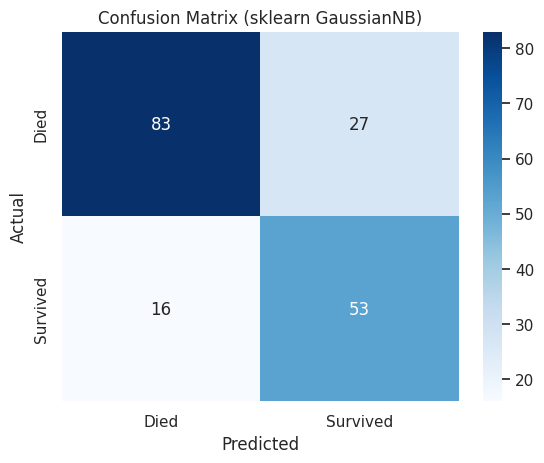

              precision    recall  f1-score   support

           0       0.84      0.75      0.79       110
           1       0.66      0.77      0.71        69

    accuracy                           0.76       179
   macro avg       0.75      0.76      0.75       179
weighted avg       0.77      0.76      0.76       179



In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# TODO: print accuracy_score for both y_pred_scratch and y_pred_sklearn
# TODO: compute confusion_matrix for y_pred_sklearn and plot it with sns.heatmap(annot=True)
# TODO: print classification_report for y_pred_sklearn
print('Accuracy (scratch): ', accuracy_score(y_test, y_pred_scratch))
print('Accuracy (sklearn): ', accuracy_score(y_test, y_pred_sklearn))

cm = confusion_matrix(y_test, y_pred_sklearn)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (sklearn GaussianNB)')
plt.show()

print(classification_report(y_test, y_pred_sklearn))

**3.6 Final Comparison: Does All That Preprocessing Actually Help?**

Train one more `GaussianNB` on a **minimally processed** baseline (just impute missing `age`, drop other categorical columns) and compare its cross-validated accuracy to Member B's fully processed pipeline from Section 3.4.

In [ ]:
# TODO: build a quick baseline: X_baseline = titanic[['pclass','age','sibsp','parch','fare']] (imputed age only, no encoding/scaling/binning)
# TODO: run the same cross_val_score(GaussianNB(), X_baseline, y, cv=5) on it
# TODO: print both mean CV accuracies side-by-side and comment on the difference

from sklearn.pipeline import make_pipeline

baseline_cols = ['pclass', 'age', 'sibsp', 'parch', 'fare']
X_baseline = titanic[baseline_cols]
y_all = titanic['survived']

# age is imputed inside a pipeline so each CV fold learns its median only from its own training part
baseline_model = make_pipeline(SimpleImputer(strategy='median'), GaussianNB())
cv_baseline = cross_val_score(baseline_model, X_baseline, y_all, cv=5)

# same comparison on exactly the same training rows Member B's pipeline used
cv_baseline_train = cross_val_score(baseline_model, titanic.loc[X_train.index, baseline_cols], y_train, cv=5)

print('Full pipeline  (train rows) mean CV acc:', round(cv_scores.mean(), 4))
print('Baseline       (train rows) mean CV acc:', round(cv_baseline_train.mean(), 4))
print('Baseline       (all rows)   mean CV acc:', round(cv_baseline.mean(), 4))

# Comment: the full pipeline beats the baseline by roughly 7 points (about 0.77 vs 0.70 on the same training rows).
# The baseline has no `sex` column, and sex is the strongest survival signal, so most of the gain comes from encoding it,
# not from scaling or power transforms (Gaussian NB is largely insensitive to feature scale).


Full pipeline  (train rows) mean CV acc: 0.7669
Baseline       (train rows) mean CV acc: 0.6966
Baseline       (all rows)   mean CV acc: 0.6768


**Compare your 3 results:** from-scratch NB, `sklearn` NB on the full pipeline, and `sklearn` NB on the raw baseline. They should mostly agree in *direction* even if the exact numbers differ slightly.

#### **Wrap-Up: Group Reflection (Answer Together)**

As a group, discuss and write your answers in the cell below:

1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?
2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?
3. Which Naive Bayes variant (`Gaussian`/`Multinomial`/`Bernoulli`/`Categorical`) would you choose for a spam-detection problem based on word counts, and why?
4. Why did we split the data into train/test **before** imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?

*Group answers here:*

1. One-hot encoding `sex` (in the ColumnTransformer) helped the most. The baseline had no sex information at all, and sex is the strongest predictor of survival. As a check, adding just a 0/1 sex column to the baseline lifted CV accuracy from about 0.70 to about 0.785, which is even a bit higher than the full pipeline (about 0.767). Scaling and the Yeo-Johnson transform barely matter for Gaussian NB because it fits a separate mean and variance per feature; the extra binned/binary versions of age and fare (`age_group_encoded`, `is_child`, `fare_level`) are redundant with `age` and `fare`, which breaks the independence assumption a little and can cost a bit of accuracy.
2. They matched exactly: both give 0.742 (233 of 314 women survived). That is expected. With probabilities computed from the same data, P(B|A)·P(A)/P(B) is an algebraic identity for the empirical proportion, so any mismatch would only come from a coding mistake or rounding. (Naive Bayes itself only becomes approximate when many features are multiplied under the independence assumption.)
3. `MultinomialNB`, because word counts are discrete non-negative counts, which is exactly the data the multinomial likelihood models (`BernoulliNB` is the alternative if we only record whether a word is present or absent). `GaussianNB` would be a poor fit for sparse counts.
4. To avoid data leakage. Imputation medians/modes, encoder categories, bin edges, power-transform parameters and scaler means/stds must be learned from the training data only. If they were fit on the whole dataset, information from the test rows would influence training, and the test score would be optimistically biased and no longer a fair estimate of performance on new passengers.
